| Concept   | On regarde quoi ?      | Signification                      |
| --------- | ---------------------- | ---------------------------------- |
| SASA      | Surface brute (Å²)     | Surface accessible                 |
| rSASA     | Surface relative (0-1) | % exposition                       |
| Surface   | rSASAm > 0.25          | Résidu exposé                      |
| Interface | ΔrSASA > 0.01          | Résidu impliqué dans l’interaction |


In [5]:
import pickle
import pandas as pd

# 1- Importing docs

In [6]:
m1_file = "2FJU_AB_m1.pkl"
m2_file = "2FJU_AB_m2.pkl"
c_file  = "2FJU_AB_c.pkl"

d_m1 = pickle.load(open(m1_file, "rb"))
d_m2 = pickle.load(open(m2_file, "rb"))
d_c  = pickle.load(open(c_file,  "rb"))

# 2- Useful functions

In [7]:
def get_chain_keys(d):
    """Return chain keys (exclude 'chains' if present)."""
    return [k for k in d.keys() if k != "chains"]

def guess_chain_map(d_m, d_c, fallback_chain):
    """
    Try to guess the chain mapping between monomer and complex by matching chain keys.
    If no match is found, return the fallback chain.
    """
    m_chains = get_chain_keys(d_m)
    c_chains = get_chain_keys(d_c)

    if len(m_chains) == 0:
        raise ValueError("No chains found in monomer.")
    if len(c_chains) == 0:
        raise ValueError("No chains found in complex.")

    cm = m_chains[0]
    if cm in c_chains:
        return cm
    return fallback_chain

def extract_residue_ids(d_chain):
    """List of residue IDs (keys) excluding 'reslist' if present."""
    return [r for r in d_chain.keys() if r != "reslist"]

def build_table(d_m, d_c, chain_m, chain_c, monomer_name, thr_surface=0.25, thr_interface=0.01):
    """
    Build a DataFrame comparing residues in monomer and complex for given chains.
    Classify residues as surface and interface based on rSASA values and thresholds.
    """
    rows = []
    res_ids = extract_residue_ids(d_m[chain_m])

    for r in res_ids:
        #Security: skip if residue not in complex data
        if chain_c not in d_c or r not in d_c[chain_c]:
            continue

        rm = d_m[chain_m][r]
        rc = d_c[chain_c][r]
        
        rSASAm = rm.get("rSASA", None)
        SASAm  = rm.get("SASA", None)
        rSASAc = rc.get("rSASA", None)
        SASAc  = rc.get("SASA", None)

        # type of residue: try multiple keys, default to "NA"
        res_type = (rm.get("resname")
                    or rm.get("AA")
                    or rm.get("type")
                    or rm.get("name")
                    or "NA")

        # if rSASA is missing in either monomer or complex, skip this residue
        if rSASAm is None or rSASAc is None:
            continue

        delta = rSASAm - rSASAc
        is_surface   = (rSASAm > thr_surface)
        is_interface = (delta  > thr_interface)

        rows.append({
            "monomer": monomer_name,
            "chain_monomer": chain_m,
            "chain_complex": chain_c,
            "res_id": r,
            "res_type": res_type,
            "rSASAm": rSASAm,
            "SASAm": SASAm,
            "rSASAc": rSASAc,
            "SASAc": SASAc,
            "delta_rSASA": delta,
            "is_surface": is_surface,
            "is_interface": is_interface
        })

    return pd.DataFrame(rows)


# 3- Choosing chains

In [8]:
print("Monomère 1 chains:", get_chain_keys(d_m1))
print("Monomère 2 chains:", get_chain_keys(d_m2))
print("Complexe chains  :", get_chain_keys(d_c))

Monomère 1 chains: ['B']
Monomère 2 chains: ['A']
Complexe chains  : ['B', 'A']


In [9]:
chain_c_m1 = guess_chain_map(d_m1, d_c, fallback_chain="A")
chain_c_m2 = guess_chain_map(d_m2, d_c, fallback_chain="B") # here the fulback is the opposite chain to see if the mapping didn't work

chain_m1 = get_chain_keys(d_m1)[0]
chain_m2 = get_chain_keys(d_m2)[0]

print("Mapping choisi:")
print("m1:", chain_m1, "-> complex:", chain_c_m1)
print("m2:", chain_m2, "-> complex:", chain_c_m2)


Mapping choisi:
m1: B -> complex: B
m2: A -> complex: A


# 4- Table construction

In [10]:
df1 = build_table(d_m1, d_c, chain_m1, chain_c_m1, monomer_name="m1")
df2 = build_table(d_m2, d_c, chain_m2, chain_c_m2, monomer_name="m2")

df = pd.concat([df1, df2], ignore_index=True)

In [11]:
df

,monomer,chain_monomer,chain_complex,res_id,res_type,rSASAm,SASAm,rSASAc,SASAc,delta_rSASA,is_surface,is_interface
0,m1,B,B,11,PRO,0.714692,98.062944,0.714692,98.062944,0.0,True,False
1,m1,B,B,12,LYS,0.919977,188.576870,0.919977,188.576870,0.0,True,False
2,m1,B,B,13,VAL,0.089422,13.589396,0.089422,13.589396,0.0,False,False
3,m1,B,B,14,LYS,0.554962,113.756053,0.554962,113.756053,0.0,True,False
4,m1,B,B,15,ALA,0.776759,84.480317,0.776759,84.480317,0.0,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
868,m2,A,A,173,ILE,0.000616,0.108192,0.000616,0.108192,0.0,False,False
869,m2,A,A,174,ARG,0.439235,104.612586,0.439235,104.612586,0.0,True,False
870,m2,A,A,175,ALA,0.293903,31.964839,0.293903,31.964839,0.0,True,False
871,m2,A,A,176,VAL,0.263810,40.091185,0.263810,40.091185,0.0,True,False


In [12]:
print(df["monomer"].unique())
print(df["chain_complex"].unique())
print(df["chain_monomer"].unique())


['m1' 'm2']
['B' 'A']
['B' 'A']


# 5- Results

In [13]:
surface_df   = df[df["is_surface"]].copy() # ça donne que les valeurs True pour is_surface (faut comprendre python)
interface_df = df[df["is_interface"]].copy() # ça donne que les valeurs True pour is_interface

print("\n--- Resume ---")
print("Total résidus analysés:", len(df))
print("Résidus SURFACE:", len(surface_df))
print("Résidus INTERFACE:", len(interface_df))



--- Resume ---
Total résidus analysés: 873
Résidus SURFACE: 385
Résidus INTERFACE: 30


In [14]:
print("\nExample interface (top 10 par ΔrSASA):")
print(interface_df.sort_values("delta_rSASA", ascending=False).head(10)[["monomer","chain_complex","res_id","res_type","rSASAm","rSASAc","delta_rSASA"]])


Example interface (top 10 par ΔrSASA):
    monomer chain_complex res_id res_type    rSASAm    rSASAc  delta_rSASA
41       m1             B     52      GLN  0.842726  0.083270     0.759456
732      m2             A     37      PHE  0.676342  0.046556     0.629786
765      m2             A     70      LEU  0.747868  0.169540     0.578328
761      m2             A     66      ARG  0.924683  0.496743     0.427940
73       m1             B     84      VAL  0.617911  0.203646     0.414264
762      m2             A     67      LEU  0.591524  0.177354     0.414170
107      m1             B    118      TYR  0.533494  0.135010     0.398484
11       m1             B     22      ARG  0.601419  0.229888     0.371532
731      m2             A     36      VAL  0.578879  0.216553     0.362326
24       m1             B     35      PRO  0.366277  0.061732     0.304545


In [15]:
print("\nExample surface (top 10 par ΔrSASA):")
print(surface_df.sort_values("delta_rSASA", ascending=True).head(10)[["monomer","chain_complex","res_id","res_type","rSASAm","rSASAc","delta_rSASA"]])


Example surface (top 10 par ΔrSASA):
    monomer chain_complex res_id res_type    rSASAm    rSASAc  delta_rSASA
190      m1             B    201      GLU  0.730393  0.730393          0.0
843      m2             A    148      GLU  0.559326  0.559326          0.0
845      m2             A    150      GLY  0.618038  0.618038          0.0
847      m2             A    152      VAL  0.498934  0.498934          0.0
848      m2             A    153      LYS  0.482370  0.482370          0.0
855      m2             A    160      LEU  0.555809  0.555809          0.0
856      m2             A    161      THR  0.579682  0.579682          0.0
857      m2             A    162      GLN  0.294358  0.294358          0.0
858      m2             A    163      ARG  0.691034  0.691034          0.0
859      m2             A    164      GLY  0.343444  0.343444          0.0


In [16]:
interface_df["monomer"].unique()

array(['m1', 'm2'], dtype=object)

# 6- CSV

In [17]:
df.to_csv("all_residues_surface_interface.csv", index=False)
surface_df.to_csv("surface_residues.csv", index=False)
interface_df.to_csv("interface_residues.csv", index=False)

print("\nCSV générés:")
print("- all_residues_surface_interface.csv")
print("- surface_residues.csv")
print("- interface_residues.csv")


CSV générés:
- all_residues_surface_interface.csv
- surface_residues.csv
- interface_residues.csv


# 7- Activité 6

In [18]:
# total number of residus in surface and interface for m1 and m2
print("\nResidus SURFACE par monomère:")
print(surface_df.groupby("monomer").size())
print("\nResidus INTERFACE par monomère:")
print(interface_df.groupby("monomer").size())


Residus SURFACE par monomère:
monomer
m1    292
m2     93
dtype: int64

Residus INTERFACE par monomère:
monomer
m1    17
m2    13
dtype: int64


In [19]:
# taille en SASA pour surface et interface pour m1 et m2 
print("\nSASA  des résidus SURFACE par monomère:")
print(surface_df.groupby("monomer")["SASAm"].sum())
print("\nSASA  des résidus INTERFACE par monomère:")
print(interface_df.groupby("monomer")["SASAm"].sum())



SASA  des résidus SURFACE par monomère:
monomer
m1    24782.909652
m2     8442.858455
Name: SASAm, dtype: float64

SASA  des résidus INTERFACE par monomère:
monomer
m1    1388.748878
m2    1127.108194
Name: SASAm, dtype: float64


In [20]:
# nombre d'occurrences des 20 acides aminés 
print(list(surface_df["res_type"].value_counts()))
print(surface_df["res_type"].unique())


[54, 40, 38, 34, 24, 23, 22, 19, 19, 19, 18, 16, 12, 12, 12, 10, 7, 5, 1]
['PRO' 'LYS' 'ALA' 'TYR' 'SER' 'GLN' 'GLY' 'ARG' 'ASP' 'GLU' 'THR' 'VAL'
 'ILE' 'MET' 'PHE' 'ASN' 'LEU' 'HIS' 'TRP']


In [21]:
surface_df["res_type"].value_counts().sort_index()

res_type
ALA    16
ARG    19
ASN    19
ASP    38
GLN    18
GLU    40
GLY    19
HIS     7
ILE     5
LEU    22
LYS    54
MET    12
PHE    12
PRO    34
SER    23
THR    24
TRP     1
TYR    10
VAL    12
Name: count, dtype: int64

In [22]:
interface_df["res_type"].value_counts().sort_index()

res_type
ALA    1
ARG    2
ASN    3
ASP    3
GLN    1
ILE    2
LEU    2
LYS    3
PHE    2
PRO    1
SER    4
TRP    1
TYR    2
VAL    3
Name: count, dtype: int64

In [23]:
# pourcentage de residus par type (hydrophobe, polaire, chargé) pour interface et suraface 
hydrophobe = ["ALA","CYS","VAL","LEU","ILE","MET","PRO","PHE","TRP"]
polaire = ["SER","THR","ASN","GLN","GLY","TYR"]
charge = ["ASP","GLU","LYS","ARG","HIS"]
print("\nPourcentage de résidus hydrophobes, polaires et chargés dans les résidus de surface:")
surface_counts = surface_df["res_type"].value_counts()
surface_total = surface_counts.sum()
for res_type in ["hydrophobe", "polaire", "chargé"]:
    if res_type == "hydrophobe":
        count = surface_counts[surface_counts.index.isin(hydrophobe)].sum()
    elif res_type == "polaire":
        count = surface_counts[surface_counts.index.isin(polaire)].sum()
    elif res_type == "chargé":
        count = surface_counts[surface_counts.index.isin(charge)].sum()
    percentage = (count / surface_total) * 100 if surface_total > 0 else 0
    print(f"{res_type.capitalize()}: {percentage:.2f}%")
print("\nPourcentage de résidus hydrophobes, polaires et chargés dans les résidus d'interface:")
interface_counts = interface_df["res_type"].value_counts()
interface_total = interface_counts.sum()
for res_type in ["hydrophobe", "polaire", "chargé"]:
    if res_type == "hydrophobe":
        count = interface_counts[interface_counts.index.isin(hydrophobe)].sum()
    elif res_type == "polaire":
        count = interface_counts[interface_counts.index.isin(polaire)].sum()
    elif res_type == "chargé":
        count = interface_counts[interface_counts.index.isin(charge)].sum()
    percentage = (count / interface_total) * 100 if interface_total > 0 else 0
    print(f"{res_type.capitalize()}: {percentage:.2f}%")


Pourcentage de résidus hydrophobes, polaires et chargés dans les résidus de surface:
Hydrophobe: 29.61%
Polaire: 29.35%
Chargé: 41.04%

Pourcentage de résidus hydrophobes, polaires et chargés dans les résidus d'interface:
Hydrophobe: 40.00%
Polaire: 33.33%
Chargé: 26.67%


# Activité 7

In [24]:
import matplotlib.pyplot as plt
import pandas as pd

In [25]:
df = pd.read_csv("Activité 6 - Résultats - 6.1.csv",header=1)

In [28]:
df["Groupe"] = df["Groupe"].ffill()

In [29]:
df.columns = ["groupe", "monomère", "taille_surface", "taille_interface"]

In [30]:
df.head()

,groupe,monomère,taille_surface,taille_interface
0,0.0,m1,107.0,21.0
1,0.0,m2,356.0,25.0
2,1.0,m1,81.0,18.0
3,1.0,m2,99.0,20.0
4,2.0,m1,45.0,15.0


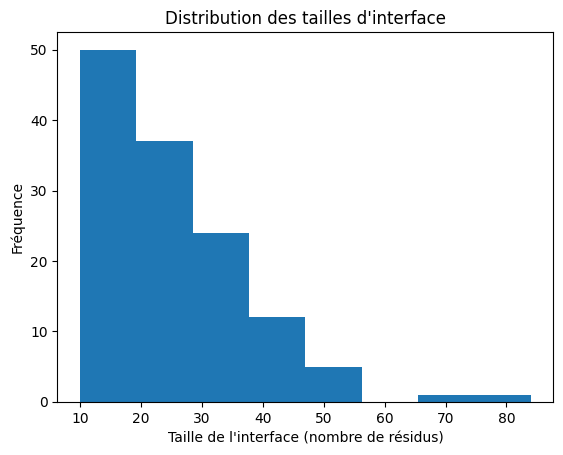

In [31]:
plt.figure()
plt.hist(df["taille_interface"].dropna(), bins=8)

plt.xlabel("Taille de l'interface (nombre de résidus)")
plt.ylabel("Fréquence")
plt.title("Distribution des tailles d'interface")

plt.show()

The distribution of interface sizes is right-skewed, with most interfaces ranging between 10 and 30 residues. A few larger interfaces are observed, including one outlier around 80 residues. The distribution is not symmetric and therefore does not follow a normal distribution, which is expected for biological size-related variables.

In [32]:
print("Moyenne :", df["taille_interface"].mean())
print("Médiane :", df["taille_interface"].median())
print("Écart-type :", df["taille_interface"].std())

Moyenne : 25.869230769230768
Médiane : 24.0
Écart-type : 12.167684014939656


In [33]:
df2 = pd.read_csv("Activité 6 - Résultats - 6.2.csv", header=1)
df2.columns = ["groupe", "monomere", "taille_surface", "taille_interface"]
df2["groupe"] = df2["groupe"].ffill()

In [34]:
df2.head()

,groupe,monomere,taille_surface,taille_interface
0,0.0,m1,10501.0,1929.0
1,0.0,m2,34918.0,1752.0
2,1.0,m1,7139.0,1814.0
3,1.0,m2,8657.0,1873.0
4,2.0,m1,3632.0,1147.0


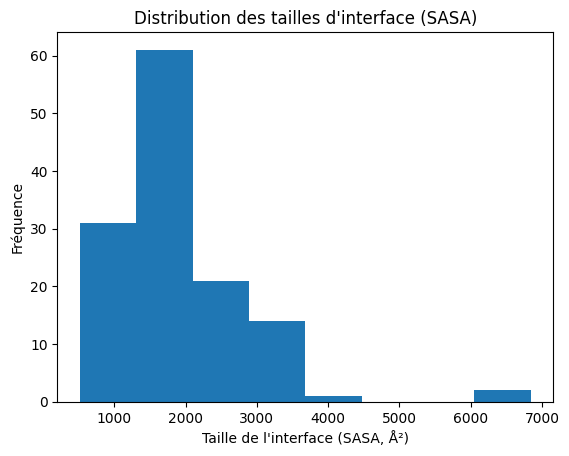

In [35]:
plt.figure()
plt.hist(df2["taille_interface"].dropna(), bins=8)

plt.xlabel("Taille de l'interface (SASA, Å²)")
plt.ylabel("Fréquence")
plt.title("Distribution des tailles d'interface (SASA)")

plt.show()

In [36]:
print("Moyenne :", df2["taille_interface"].mean())
print("Médiane :", df2["taille_interface"].median())
print("Écart-type :", df2["taille_interface"].std())

Moyenne : 1895.1787367846155
Médiane : 1661.5
Écart-type : 917.6876274657334


The distribution of interface sizes expressed in SASA (Å²) is positively skewed. Most interfaces range between 1000 and 2500 Å². The mean (≈1895 Å²) is higher than the median (≈1661 Å²), confirming the right-skewed distribution. A few large interfaces significantly increase the dispersion (SD ≈ 918 Å²). This variability is consistent with biological expectations, as protein-protein interfaces can vary considerably in size.

In [37]:
df["ratio_interface_surface"] = (df["taille_interface"] / df["taille_surface"])

In [38]:
df[["taille_surface", "taille_interface", "ratio_interface_surface"]].head()

,taille_surface,taille_interface,ratio_interface_surface
0,107.0,21.0,0.196262
1,356.0,25.0,0.070225
2,81.0,18.0,0.222222
3,99.0,20.0,0.202020
4,45.0,15.0,0.333333


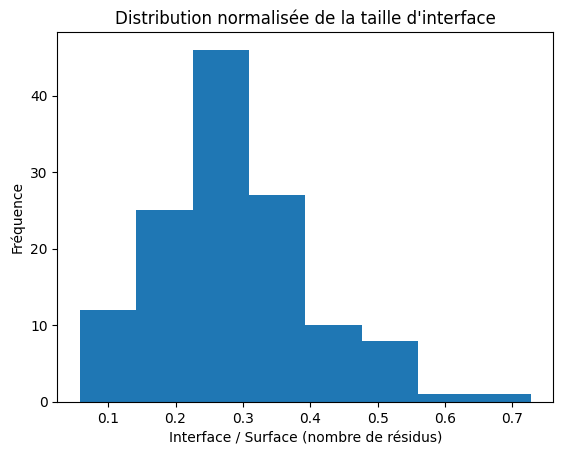

In [39]:
plt.figure()
plt.hist(df["ratio_interface_surface"].dropna(), bins=8)

plt.xlabel("Interface / Surface (nombre de résidus)")
plt.ylabel("Fréquence")
plt.title("Distribution normalisée de la taille d'interface")

plt.show()

In [40]:
print("Moyenne :", df["ratio_interface_surface"].mean())
print("Médiane :", df["ratio_interface_surface"].median())
print("Écart-type :", df["ratio_interface_surface"].std())

Moyenne : 0.28757083967285585
Médiane : 0.27793103448275863
Écart-type : 0.11649940583952338


The normalized interface size (interface residues divided by surface residues) shows that most complexes use approximately 20–35% of their surface to form the interface. The distribution is slightly right-skewed, indicating that while most interfaces occupy a moderate fraction of the surface, a few complexes exhibit relatively larger interaction surfaces.

In [41]:
df3 = pd.read_csv("Activité 6 - Résultats - 6.3.csv")

In [45]:
#Renommer les colonnes pour avoir des noms clairs
# Parce que dans le CSV, les 2 premières colonnes ne sont pas bien nommées par pandas.
# Ici :
# - colonne 1 = groupe
# - colonne 2 = type de ligne ("surface m1+m2", "interface m1+m2", ...)
# - colonnes suivantes = 20 acides aminés
# - dernière colonne = total
df3.columns = [
    "groupe", "type",
    "ALA", "ARG", "ASN", "ASP", "CYS",
    "GLN", "GLU", "GLY", "HIS", "ILE",
    "LEU", "LYS", "MET", "PHE", "PRO",
    "SER", "THR", "TRP", "TYR", "VAL",
    "TOT"
]

In [47]:
print("Aperçu du tableau :")
print(df3.head())

print("\nNoms des colonnes :")
print(df3.columns)

Aperçu du tableau :
   groupe             type  ALA  ARG  ASN  ASP  CYS  GLN  GLU  GLY  ...  LYS  \
0  Groupe              NaN  ALA  ARG  ASN  ASP  CYS  GLN  GLU  GLY  ...  LYS   
1       0    surface m1+m2   26   35   14   52    0   26   54   41  ...   51   
2     NaN  interface m1+m2    1    7    1    3    0    3    3    8  ...    3   
3       1    surface m1+m2   21   22    3    8    0   10   21   15  ...    7   
4     NaN  interface m1+m2    1    5    2    2    0    0    7    0  ...    5   

   MET  PHE  PRO  SER  THR  TRP  TYR  VAL  TOT  
0  MET  PHE  PRO  SER  THR  TRP  TYR  VAL  TOT  
1    4    8   31   31   21    2    8   17  463  
2    2    0    4    3    1    1    2    1   46  
3    1    1   13   19   10    2    0   11  180  
4    1    2    3    3    1    0    1    1   38  

[5 rows x 23 columns]

Noms des colonnes :
Index(['groupe', 'type', 'ALA', 'ARG', 'ASN', 'ASP', 'CYS', 'GLN', 'GLU',
       'GLY', 'HIS', 'ILE', 'LEU', 'LYS', 'MET', 'PHE', 'PRO', 'SER', 'THR',
       'TR

In [48]:
# enlever la ligne inutile du header Excel
df3 = df3.iloc[1:]

# propager les valeurs de groupe
df3["groupe"] = df3["groupe"].ffill()

# réinitialiser les index
df3 = df3.reset_index(drop=True)

In [49]:
print("Aperçu du tableau :")
print(df3.head())

Aperçu du tableau :
  groupe             type ALA ARG ASN ASP CYS GLN GLU GLY  ... LYS MET PHE  \
0      0    surface m1+m2  26  35  14  52   0  26  54  41  ...  51   4   8   
1      0  interface m1+m2   1   7   1   3   0   3   3   8  ...   3   2   0   
2      1    surface m1+m2  21  22   3   8   0  10  21  15  ...   7   1   1   
3      1  interface m1+m2   1   5   2   2   0   0   7   0  ...   5   1   2   
4      2    surface m1+m2  17   4   7  11   1   2  15  11  ...  11   1   2   

  PRO SER THR TRP TYR VAL  TOT  
0  31  31  21   2   8  17  463  
1   4   3   1   1   2   1   46  
2  13  19  10   2   0  11  180  
3   3   3   1   0   1   1   38  
4   3   5   9   0   1   6  115  

[5 rows x 23 columns]


In [51]:
# Récupérer les lignes TOTAL utiles

# Dans le tableau, en bas, il y a :
# - TOTAL / surface m1+m2
# - TOTAL / interface m1+m2
# - TOTAL / surface+interface
#
# Pour la propension relative, on a seulement besoin de :
# - TOTAL surface m1+m2
# - TOTAL interface m1+m2

total_rows = df3[df3["groupe"].astype(str).str.contains("TOTAL", case=False, na=False)]

print("\nLignes TOTAL trouvées :")
print(total_rows)

# Ligne TOTAL surface
surface_row = total_rows[total_rows["type"].astype(str).str.contains("surface m1\\+m2", regex=True, na=False)]

# Ligne TOTAL interface
interface_row = total_rows[total_rows["type"].astype(str).str.contains("interface m1\\+m2", regex=True, na=False)]

print("\nLigne TOTAL surface :")
print(surface_row)

print("\nLigne TOTAL interface :")
print(interface_row)



Lignes TOTAL trouvées :
    groupe               type  ALA   ARG  ASN   ASP  CYS   GLN   GLU   GLY  \
132  TOTAL      surface m1+m2  766   849  796  1095   85   826  1320  1050   
133  TOTAL    interface m1+m2  177   204  202   193   74   180   227   244   
134  TOTAL  surface+interface  943  1053  998  1288  159  1006  1547  1294   

     ...   LYS  MET  PHE  PRO   SER   THR  TRP  TYR  VAL    TOT  
132  ...  1308  176  218  793  1076   903   88  357  505  13403  
133  ...   220   64  117  151   245   181   70  173  186   3383  
134  ...  1528  240  335  944  1321  1084  158  530  691  16786  

[3 rows x 23 columns]

Ligne TOTAL surface :
    groupe           type  ALA  ARG  ASN   ASP CYS  GLN   GLU   GLY  ...  \
132  TOTAL  surface m1+m2  766  849  796  1095  85  826  1320  1050  ...   

      LYS  MET  PHE  PRO   SER  THR TRP  TYR  VAL    TOT  
132  1308  176  218  793  1076  903  88  357  505  13403  

[1 rows x 23 columns]

Ligne TOTAL interface :
    groupe             type  ALA 

In [52]:
# Définir la liste des 20 acides aminés

aa_cols = [
    "ALA", "ARG", "ASN", "ASP", "CYS",
    "GLN", "GLU", "GLY", "HIS", "ILE",
    "LEU", "LYS", "MET", "PHE", "PRO",
    "SER", "THR", "TRP", "TYR", "VAL"
]

# Extraire les comptages surface et interface

# .iloc[0] car surface_row et interface_row sont des DataFrames avec une seule ligne
surface_counts = surface_row[aa_cols].iloc[0].astype(float)
interface_counts = interface_row[aa_cols].iloc[0].astype(float)

print("\nComptages surface :")
print(surface_counts)

print("\nComptages interface :")
print(interface_counts)


Comptages surface :
ALA     766.0
ARG     849.0
ASN     796.0
ASP    1095.0
CYS      85.0
GLN     826.0
GLU    1320.0
GLY    1050.0
HIS     311.0
ILE     290.0
LEU     591.0
LYS    1308.0
MET     176.0
PHE     218.0
PRO     793.0
SER    1076.0
THR     903.0
TRP      88.0
TYR     357.0
VAL     505.0
Name: 132, dtype: float64

Comptages interface :
ALA    177.0
ARG    204.0
ASN    202.0
ASP    193.0
CYS     74.0
GLN    180.0
GLU    227.0
GLY    244.0
HIS    113.0
ILE    147.0
LEU    215.0
LYS    220.0
MET     64.0
PHE    117.0
PRO    151.0
SER    245.0
THR    181.0
TRP     70.0
TYR    173.0
VAL    186.0
Name: 133, dtype: float64


In [53]:

# Calculer les fractions f_i,S et f_i,I

# f_i,S = nombre de résidus i à la surface / nombre total de résidus de surface
# f_i,I = nombre de résidus i à l'interface / nombre total de résidus d'interface
f_surface = surface_counts / surface_counts.sum()
f_interface = interface_counts / interface_counts.sum()

print("\nFractions à la surface :")
print(f_surface)

print("\nFractions à l'interface :")
print(f_interface)



Fractions à la surface :
ALA    0.057151
ARG    0.063344
ASN    0.059390
ASP    0.081698
CYS    0.006342
GLN    0.061628
GLU    0.098485
GLY    0.078341
HIS    0.023204
ILE    0.021637
LEU    0.044095
LYS    0.097590
MET    0.013131
PHE    0.016265
PRO    0.059166
SER    0.080281
THR    0.067373
TRP    0.006566
TYR    0.026636
VAL    0.037678
Name: 132, dtype: float64

Fractions à l'interface :
ALA    0.052320
ARG    0.060302
ASN    0.059710
ASP    0.057050
CYS    0.021874
GLN    0.053207
GLU    0.067100
GLY    0.072125
HIS    0.033402
ILE    0.043453
LEU    0.063553
LYS    0.065031
MET    0.018918
PHE    0.034585
PRO    0.044635
SER    0.072421
THR    0.053503
TRP    0.020692
TYR    0.051138
VAL    0.054981
Name: 133, dtype: float64


In [55]:
import numpy as np
# Calculer la propension relative

# Formule :
# p_i = log2( f_i,I / f_i,S )
#
# Attention :
# si un acide aminé a une fréquence nulle à l'interface ou à la surface,
# le log2 peut poser problème.
# On ajoute donc une petite constante epsilon pour éviter division par 0.
epsilon = 1e-9
propensity = np.log2((f_interface + epsilon) / (f_surface + epsilon))

print("\nPropensions relatives :")
print(propensity)




Propensions relatives :
ALA   -0.127414
ARG   -0.071015
ASN    0.007768
ASP   -0.518077
CYS    1.786243
GLN   -0.211964
GLU   -0.553593
GLY   -0.119255
HIS    0.525589
ILE    1.005944
LEU    0.527359
LYS   -0.585606
MET    0.526749
PHE    1.088361
PRO   -0.406591
SER   -0.148644
THR   -0.332555
TRP    1.656032
TYR    0.941029
VAL    0.545200
dtype: float64


In [56]:
# 9) Mettre le résultat dans un DataFrame propre
results = pd.DataFrame({
    "Acide_amine": aa_cols,
    "f_surface": f_surface.values,
    "f_interface": f_interface.values,
    "propension_relative": propensity.values
})

print("\nTableau final des propensions :")
print(results)


Tableau final des propensions :
   Acide_amine  f_surface  f_interface  propension_relative
0          ALA   0.057151     0.052320            -0.127414
1          ARG   0.063344     0.060302            -0.071015
2          ASN   0.059390     0.059710             0.007768
3          ASP   0.081698     0.057050            -0.518077
4          CYS   0.006342     0.021874             1.786243
5          GLN   0.061628     0.053207            -0.211964
6          GLU   0.098485     0.067100            -0.553593
7          GLY   0.078341     0.072125            -0.119255
8          HIS   0.023204     0.033402             0.525589
9          ILE   0.021637     0.043453             1.005944
10         LEU   0.044095     0.063553             0.527359
11         LYS   0.097590     0.065031            -0.585606
12         MET   0.013131     0.018918             0.526749
13         PHE   0.016265     0.034585             1.088361
14         PRO   0.059166     0.044635            -0.406591
15     

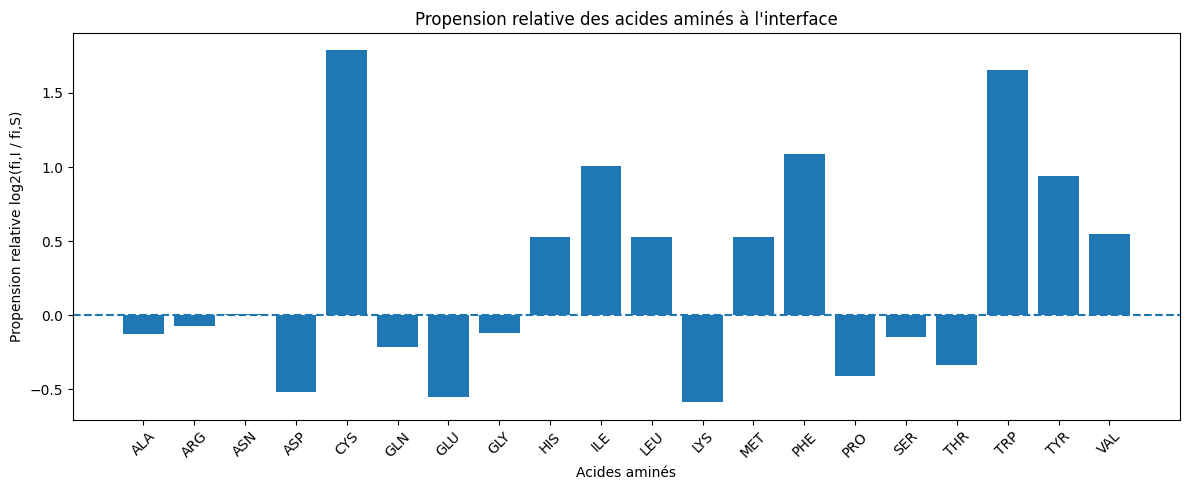

In [57]:
plt.figure(figsize=(12, 5))
plt.bar(results["Acide_amine"], results["propension_relative"])

# Ligne horizontale à y=0 pour séparer enrichissement / appauvrissement
plt.axhline(0, linestyle="--")

plt.xlabel("Acides aminés")
plt.ylabel("Propension relative log2(fi,I / fi,S)")
plt.title("Propension relative des acides aminés à l'interface")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [58]:
df4 = pd.read_csv("Activité 6 - Résultats - 6.4.csv")

In [59]:
df4.columns = ["groupe","type","HP","POL","CHG","TOT"]

In [60]:
df4 = df4.iloc[1:]

df4["groupe"] = df4["groupe"].ffill()

df4 = df4.reset_index(drop=True)

In [67]:
df4[["HP","POL","CHG"]] = df4[["HP","POL","CHG"]].apply(pd.to_numeric)

In [68]:
#Séparer surface et interface
surface = df4[df4["type"].str.contains("surface")]
interface = df4[df4["type"].str.contains("interface")]

In [69]:
#Extraire les distributions
hp_surface = surface["HP"]
hp_interface = interface["HP"]

pol_surface = surface["POL"]
pol_interface = interface["POL"]

chg_surface = surface["CHG"]
chg_interface = interface["CHG"]

C:\Users\firda\AppData\Local\Temp\ipykernel_48940\1032185857.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels)


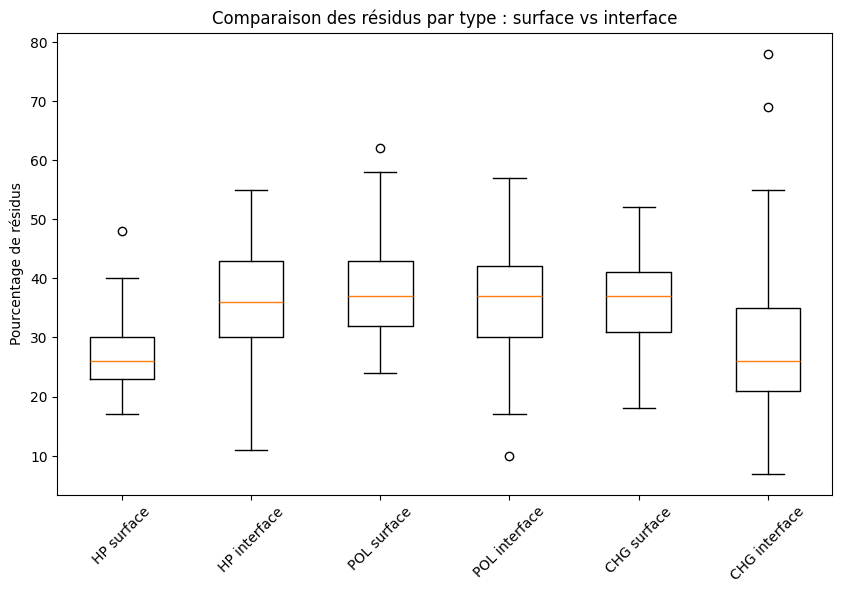

In [70]:
plt.figure(figsize=(10,6))

data = [
    hp_surface, hp_interface,
    pol_surface, pol_interface,
    chg_surface, chg_interface
]

labels = [
    "HP surface","HP interface",
    "POL surface","POL interface",
    "CHG surface","CHG interface"
]

plt.boxplot(data, labels=labels)

plt.ylabel("Pourcentage de résidus")
plt.title("Comparaison des résidus par type : surface vs interface")

plt.xticks(rotation=45)

plt.show()

- Donc les résidus hydrophobes sont plus fréquents à l’interface.
- Les résidus polaires restent souvent exposés au solvant.
- Les résidus chargés préfèrent la surface exposée au solvant plutôt que les interfaces.

| Type        | Interface | Surface |
| ----------- | --------- | ------- |
| Hydrophobes | ↑         | ↓       |
| Polaires    | ~         | ~       |
| Chargés     | ↓         | ↑       |
